# 04 · Merge two oscilloscope channel files into one analysis file (helper)

**Purpose.** The oscilloscope exports each channel as its own CSV file with a header block. This helper reads the trigger channel and the output channel, checks that they share one time axis, cuts the record at the rising edge of the Arduino's 50 ms trigger pulse, and writes the three-column file (`TIME, CH2, CH1`) that notebook 05 analyses.

**In the report.** Chapter 3, Sec. 3.3 (recording). Supplementary: it documents how the `newexpdata - <rate>ohms.csv` files were made.

## Method

1. Read each Tektronix CSV: skip the header lines up to the line that starts with `TIME`, then read time (s) and voltage (V).
2. Check that both files have the same number of points and the same time stamps.
3. Find the trigger pulse on the trigger channel: the rising edges through half its full range, keeping the one followed by a high level lasting `PULSE_WIDTH` within the tolerance. The 50 ms pulse is the only such pulse.
4. Keep everything from the sample at the rising edge onwards, so the pulse itself stays in the file (the analysis needs its falling edge as $t_0$).
5. Optionally stop at `END_TIME`. Write `TIME, CH2, CH1` with a header line.

## Requirements

Python 3.9+, `numpy`, `pandas`, `matplotlib`.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
TRIGGER_FILE = "../data/stage2/raw_scope/TEK00022.CSV"   # channel 2: Arduino trigger (pulse 0 -> 5 V)
OUTPUT_FILE  = "../data/stage2/raw_scope/TEK00023.CSV"   # channel 1: oscillator output
MERGED_FILE  = "outputs/04_merge/merged_1kohms.csv"      # result (3 columns: TIME, CH2, CH1)
PULSE_WIDTH  = 0.050       # s, width of the trigger pulse
WIDTH_TOL    = 0.5         # accept pulses within +/- 50 % of PULSE_WIDTH
END_TIME     = None        # s on the scope's time axis to stop at, or None to keep everything to the end
COMPARE_WITH = "../data/stage2/newexpdata - 1kohms.csv"   # optional: an existing merged file to compare with, or None

## 1. Read the two channel files

In [2]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
os.makedirs(os.path.dirname(MERGED_FILE) or ".", exist_ok=True)

def read_tek(path):
    # Tektronix TBS2000 CSV: header block, then a line starting with 'TIME', then time,voltage rows.
    with open(path) as fh:
        lines = fh.read().splitlines()
    k = next(i for i, l in enumerate(lines) if l.startswith("TIME"))
    d = pd.read_csv(path, skiprows=k + 1, header=None, names=["t", "v"]).astype(float)
    return d.t.to_numpy(), d.v.to_numpy()

t2, ch2 = read_tek(TRIGGER_FILE); t1, ch1 = read_tek(OUTPUT_FILE)
if len(t1) != len(t2) or not np.allclose(t1, t2):
    raise ValueError("The two files do not share one time axis: were they saved from the same acquisition?")
dt = np.median(np.diff(t1))
print(f"{len(t1)} points, sampling interval {dt*1e3:.3f} ms, record {t1[0]:.3f} to {t1[-1]:.3f} s")

200000 points, sampling interval 0.800 ms, record -80.000 to 79.999 s


## 2. Find the trigger pulse and cut

trigger pulse: rising edge at -37.2896 s, width 50.4 ms
wrote outputs/04_merge/merged_1kohms.csv: 146612 rows from t = -37.2896 s


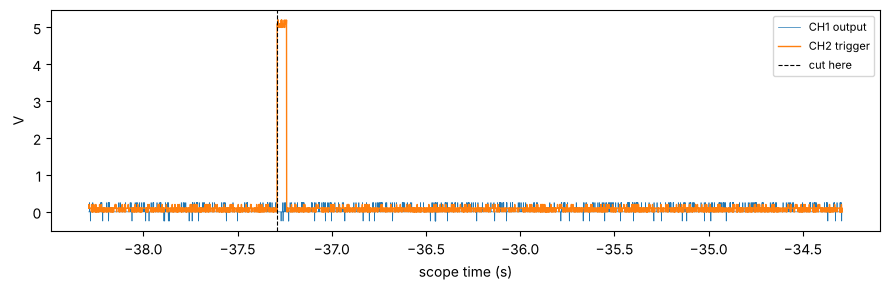

In [3]:
thr = 0.5 * (ch2.max() + ch2.min())
hi = ch2 > thr
rises = np.where(~hi[:-1] & hi[1:])[0] + 1
falls = np.where(hi[:-1] & ~hi[1:])[0] + 1
pulse = None
for r in rises:
    f = falls[falls > r]
    if len(f) and abs((t2[f[0]] - t2[r]) - PULSE_WIDTH) <= WIDTH_TOL * PULSE_WIDTH:
        pulse = (r, f[0]); break
if pulse is None:
    raise ValueError("No trigger pulse of the expected width found on the trigger channel.")
i0 = pulse[0]
i1 = len(t1) if END_TIME is None else np.searchsorted(t1, END_TIME)
merged = pd.DataFrame({"TIME": t1[i0:i1], "CH2": ch2[i0:i1], "CH1": ch1[i0:i1]})
merged.to_csv(MERGED_FILE, index=False)
print(f"trigger pulse: rising edge at {t2[pulse[0]]:.4f} s, width {(t2[pulse[1]]-t2[pulse[0]])*1e3:.1f} ms")
print(f"wrote {MERGED_FILE}: {len(merged)} rows from t = {merged.TIME.iloc[0]:.4f} s")

fig, ax = plt.subplots(figsize=(9, 3))
s = slice(max(i0 - int(1 / dt), 0), i0 + int(3 / dt))
ax.plot(t1[s], ch1[s], lw=0.5, label="CH1 output"); ax.plot(t2[s], ch2[s], lw=1, label="CH2 trigger")
ax.axvline(t2[i0], color="k", ls="--", lw=0.8, label="cut here"); ax.set_xlabel("scope time (s)"); ax.set_ylabel("V"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## Check against the file used in the report

In [4]:
if COMPARE_WITH:
    ref = pd.read_csv(COMPARE_WITH)
    n = min(len(ref), len(merged))
    same_ch1 = np.array_equal(ref.iloc[:n, 2].to_numpy(), merged.CH1.to_numpy()[:n])
    same_start = abs(ref.iloc[0, 0] - merged.TIME.iloc[0]) < 1e-3
    print(("PASS" if same_ch1 and same_start else "FAIL") +
          f" merged file starts at the same time and has identical CH1 samples over the {n} rows of the report's file")
    print(f"(the report's file stops {len(merged) - len(ref)} samples earlier: its end was trimmed by hand, which does not affect the analysis)")

PASS merged file starts at the same time and has identical CH1 samples over the 133347 rows of the report's file
(the report's file stops 13265 samples earlier: its end was trimmed by hand, which does not affect the analysis)


## Using your own files

Point `TRIGGER_FILE` and `OUTPUT_FILE` at the two channel CSVs of one acquisition. If your trigger pulse has a different width, change `PULSE_WIDTH`. Files from other oscilloscopes work if they contain a line starting with `TIME` before the data; otherwise adapt `read_tek`.